In [3]:
# ===========================
# CELL 1 : INSTALL LIBRARIES
# ===========================

!pip -q install sentence-transformers scikit-learn joblib pandas numpy matplotlib tqdm

In [4]:
# ==========================================
# CELL 2 : IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import joblib
import os
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    hamming_loss,
    f1_score,
    precision_score,
    recall_score
)

from sentence_transformers import SentenceTransformer

print("✅ Libraries Imported Successfully")

✅ Libraries Imported Successfully


In [5]:
# ==========================================
# CELL 3 : CHECK GPU
# ==========================================

import torch

print("=" * 50)

if torch.cuda.is_available():
    print("✅ GPU Available")
    print("GPU Name :", torch.cuda.get_device_name(0))
else:
    print("❌ GPU Not Available")

print("=" * 50)

✅ GPU Available
GPU Name : Tesla T4


In [6]:
# ==========================================
# CELL 4 : MOUNT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

print("✅ Google Drive Mounted Successfully")

Mounted at /content/drive
✅ Google Drive Mounted Successfully


In [7]:
# ==========================================
# CELL 5 : LOAD DATASET
# ==========================================

import os
import pandas as pd
import numpy as np
import joblib

# Folder containing the saved files
DATA_PATH = "/content/drive/MyDrive/FIRE"

# Check files
print("Files in FIRE folder:")
print(os.listdir(DATA_PATH))

# Load files
case_df = pd.read_pickle(os.path.join(DATA_PATH, "case_df.pkl"))
sentence_df = pd.read_pickle(os.path.join(DATA_PATH, "sentence_df.pkl"))
y = np.load(os.path.join(DATA_PATH, "y.npy"))
mlb = joblib.load(os.path.join(DATA_PATH, "mlb.pkl"))

print("\n✅ Files loaded successfully!")

print("\nCase Data Shape:", case_df.shape)
print("Sentence Data Shape:", sentence_df.shape)
print("Label Matrix Shape:", y.shape)
print("IPC Labels:", mlb.classes_)

Files in FIRE folder:
['sentence_df.pkl', 'y.npy', 'case_df.pkl', 'mlb.pkl', 'models']

✅ Files loaded successfully!

Case Data Shape: (525, 3)
Sentence Data Shape: (2168, 4)
Label Matrix Shape: (525, 7)
IPC Labels: ['IPC 147' 'IPC 201' 'IPC 302' 'IPC 376' 'IPC 420' 'IPC 498A' 'IPC 506']


In [8]:
# ==========================================
# CHECK DATASET COLUMNS
# ==========================================

print(case_df.columns)

print("\n")

print(case_df.head())

Index(['doc_id', 'fact', 'ipc_sections'], dtype='object')


              doc_id                                               fact  \
0  2013.INSC.228.txt   The facts which are essential to be stated fo...   
1  1996.INSC.902.txt   16 Praveen Chandra was the Divisional Forest ...   
2  2003.INSC.675.txt   Law was set in motion by PW-1(Chanakya) on th...   
3  2009.INSC.116.txt   The incident leading to the prosecution of th...   
4  2002.INSC.528.txt   , the complainant Abdul Jabbar s/o Sheikh Mun...   

  ipc_sections  
0    [IPC 147]  
1    [IPC 147]  
2    [IPC 147]  
3    [IPC 147]  
4    [IPC 147]  


In [9]:
# ==========================================
# CELL 6 : TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Input text
X = case_df["fact"]

# Output labels
Y = y

# Train-Test Split
train_texts, test_texts, train_labels, test_labels = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("✅ Train-Test Split Completed\n")

print("Training Samples :", len(train_texts))
print("Testing Samples  :", len(test_texts))

print("\nTrain Labels Shape :", train_labels.shape)
print("Test Labels Shape  :", test_labels.shape)

✅ Train-Test Split Completed

Training Samples : 420
Testing Samples  : 105

Train Labels Shape : (420, 7)
Test Labels Shape  : (105, 7)


In [10]:
# ==========================================
# CELL 7 : LOAD SENTENCE TRANSFORMER
# ==========================================

from sentence_transformers import SentenceTransformer
import torch

# Use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using Device:", device)

model = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device=device
)

print("\n✅ Sentence Transformer Loaded Successfully!")

Using Device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


✅ Sentence Transformer Loaded Successfully!


In [11]:
# ==========================================
# CELL 8 : GENERATE SENTENCE EMBEDDINGS
# ==========================================

print("Generating training embeddings...")

train_embeddings = model.encode(
    train_texts.tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("\nGenerating testing embeddings...")

test_embeddings = model.encode(
    test_texts.tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("\n✅ Embeddings Generated Successfully!")

print("Training Embeddings Shape :", train_embeddings.shape)
print("Testing Embeddings Shape  :", test_embeddings.shape)

Generating training embeddings...


Batches:   0%|          | 0/14 [00:00<?, ?it/s]


Generating testing embeddings...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]


✅ Embeddings Generated Successfully!
Training Embeddings Shape : (420, 384)
Testing Embeddings Shape  : (105, 384)


In [12]:
# ==========================================
# CELL 9 : TRAIN MULTI-LABEL CLASSIFIER
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

classifier = OneVsRestClassifier(
    LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

classifier.fit(train_embeddings, train_labels)

print("\n✅ Classifier Trained Successfully!")


✅ Classifier Trained Successfully!


In [13]:
# ==========================================
# CELL 10 : MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss
)

# Make predictions
predictions = classifier.predict(test_embeddings)

print("=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

# Metrics
accuracy = accuracy_score(test_labels, predictions)
precision = precision_score(test_labels, predictions, average="macro", zero_division=0)
recall = recall_score(test_labels, predictions, average="macro", zero_division=0)
f1 = f1_score(test_labels, predictions, average="macro", zero_division=0)
hamming = hamming_loss(test_labels, predictions)

print(f"Accuracy      : {accuracy:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"Macro F1      : {f1:.4f}")
print(f"Hamming Loss  : {hamming:.4f}")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        test_labels,
        predictions,
        target_names=mlb.classes_,
        zero_division=0
    )
)

MODEL PERFORMANCE
Accuracy      : 0.2762
Precision     : 0.5209
Recall        : 0.8017
Macro F1      : 0.6277
Hamming Loss  : 0.1633

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     IPC 147       0.53      0.80      0.64        20
     IPC 201       0.35      0.67      0.46        12
     IPC 302       0.50      0.81      0.62        31
     IPC 376       0.68      1.00      0.81        15
     IPC 420       0.75      1.00      0.86        15
    IPC 498A       0.60      0.80      0.69        15
     IPC 506       0.23      0.54      0.33        13

   micro avg       0.50      0.81      0.62       121
   macro avg       0.52      0.80      0.63       121
weighted avg       0.53      0.81      0.64       121
 samples avg       0.55      0.82      0.63       121



In [14]:
# ==========================================
# CELL 11 : SAVE TRAINED MODEL
# ==========================================

import os
import joblib

# Folder to save the trained model
MODEL_PATH = "/content/drive/MyDrive/FIRE/models"

# Create the folder if it doesn't exist
os.makedirs(MODEL_PATH, exist_ok=True)

# Save the classifier
joblib.dump(
    classifier,
    os.path.join(MODEL_PATH, "ipc_classifier.pkl")
)

# Save the MultiLabelBinarizer
joblib.dump(
    mlb,
    os.path.join(MODEL_PATH, "mlb.pkl")
)

print("✅ Model saved successfully!")

print("\nSaved Files:")
print(os.listdir(MODEL_PATH))

✅ Model saved successfully!

Saved Files:
['ipc_classifier.pkl', 'mlb.pkl']


In [15]:
# ==========================================
# CELL 12 : LOAD SAVED MODEL
# ==========================================

import os
import joblib

MODEL_PATH = "/content/drive/MyDrive/FIRE/models"

# Load the trained classifier
loaded_classifier = joblib.load(
    os.path.join(MODEL_PATH, "ipc_classifier.pkl")
)

# Load the MultiLabelBinarizer
loaded_mlb = joblib.load(
    os.path.join(MODEL_PATH, "mlb.pkl")
)

print("✅ Saved model loaded successfully!")

print("\nNumber of IPC Labels:", len(loaded_mlb.classes_))
print("\nIPC Labels:")
print(loaded_mlb.classes_)

✅ Saved model loaded successfully!

Number of IPC Labels: 7

IPC Labels:
['IPC 147' 'IPC 201' 'IPC 302' 'IPC 376' 'IPC 420' 'IPC 498A' 'IPC 506']


In [16]:
# ==========================================
# CELL 13 : PREDICT IPC SECTIONS
# ==========================================

# Enter a new legal case here
legal_case = """
The accused entered the victim's house at night,
attacked him with a knife causing multiple injuries,
and later attempted to hide the weapon.
"""

# Generate embedding
case_embedding = model.encode(
    [legal_case],
    convert_to_numpy=True
)

# Predict IPC sections
prediction = loaded_classifier.predict(case_embedding)

# Convert prediction back to IPC labels
predicted_ipcs = loaded_mlb.inverse_transform(prediction)

print("=" * 60)
print("PREDICTED IPC SECTIONS")
print("=" * 60)

if len(predicted_ipcs[0]) == 0:
    print("No IPC section predicted.")
else:
    for ipc in predicted_ipcs[0]:
        print(f"✓ {ipc}")

PREDICTED IPC SECTIONS
✓ IPC 376
✓ IPC 506


In [17]:
# ==========================================
# CELL 14 : SHOW PREDICTION CONFIDENCE
# ==========================================

# Get prediction probabilities
probabilities = loaded_classifier.predict_proba(case_embedding)

print("=" * 60)
print("IPC PREDICTION CONFIDENCE")
print("=" * 60)

for ipc, prob in zip(loaded_mlb.classes_, probabilities[0]):
    print(f"{ipc:<10} : {prob:.4f} ({prob*100:.2f}%)")

IPC PREDICTION CONFIDENCE
IPC 147    : 0.3188 (31.88%)
IPC 201    : 0.2219 (22.19%)
IPC 302    : 0.3566 (35.66%)
IPC 376    : 0.5239 (52.39%)
IPC 420    : 0.0599 (5.99%)
IPC 498A   : 0.3336 (33.36%)
IPC 506    : 0.5102 (51.02%)


In [18]:
print(sentence_df.columns)

Index(['doc_id', 'sentence', 'ipc', 'is_evidence'], dtype='object')


In [19]:
# ==========================================
# CELL 15 : EXPLAINABILITY (EVIDENCE RETRIEVAL)
# ==========================================

from sklearn.metrics.pairwise import cosine_similarity

print("Generating embeddings for evidence sentences...")

# Generate embeddings for all evidence sentences
evidence_embeddings = model.encode(
    sentence_df["sentence"].tolist(),
    batch_size=32,
    convert_to_numpy=True,
    show_progress_bar=True
)

print("\n✅ Evidence embeddings generated!")

# Compute similarity
similarity_scores = cosine_similarity(
    case_embedding,
    evidence_embeddings
)[0]

# Top 5 evidence sentences
top_k = 5
top_indices = similarity_scores.argsort()[-top_k:][::-1]

print("\n" + "="*70)
print("TOP 5 SUPPORTING EVIDENCE")
print("="*70)

for rank, idx in enumerate(top_indices, start=1):

    print(f"\nEvidence {rank}")
    print("-"*70)
    print(f"Document : {sentence_df.iloc[idx]['doc_id']}")
    print(f"IPC       : {sentence_df.iloc[idx]['ipc']}")
    print(f"Similarity: {similarity_scores[idx]:.4f}")
    print("\nSentence:")
    print(sentence_df.iloc[idx]["sentence"])

Generating embeddings for evidence sentences...


Batches:   0%|          | 0/68 [00:00<?, ?it/s]


✅ Evidence embeddings generated!

TOP 5 SUPPORTING EVIDENCE

Evidence 1
----------------------------------------------------------------------
Document : 2002.INSC.527.txt
IPC       : IPC 147
Similarity: 0.6455

Sentence:
All the accused persons were armed with deadly weapons and they attacked the members of the victims' family who were totally unarmed and were sleeping at night in the open.

Evidence 2
----------------------------------------------------------------------
Document : 1996.INSC.1583.txt
IPC       : IPC 498A
Similarity: 0.6335

Sentence:
 on that fateful night apart from the victim only the accused ware in the house.

Evidence 3
----------------------------------------------------------------------
Document : 2008.INSC.1556.txt
IPC       : IPC 376
Similarity: 0.6042

Sentence:
Then appellants took away the prosecutrix to the upper room of the house and committed rape repeatedly in the night.

Evidence 4
-------------------------------------------------------------------

In [20]:
# ==========================================
# CELL 16 : COMPLETE PREDICTION PIPELINE
# ==========================================

from sklearn.metrics.pairwise import cosine_similarity

def predict_case(legal_text, top_k=5):

    print("="*80)
    print("INPUT LEGAL CASE")
    print("="*80)
    print(legal_text)

    # --------------------------------------------------
    # Generate embedding
    # --------------------------------------------------

    case_embedding = model.encode(
        [legal_text],
        convert_to_numpy=True
    )

    # --------------------------------------------------
    # Predict IPC Sections
    # --------------------------------------------------

    prediction = loaded_classifier.predict(case_embedding)
    predicted_labels = loaded_mlb.inverse_transform(prediction)

    print("\n")
    print("="*80)
    print("PREDICTED IPC SECTIONS")
    print("="*80)

    if len(predicted_labels[0]) == 0:
        print("No IPC Section Predicted.")
    else:
        for ipc in predicted_labels[0]:
            print(f"✓ {ipc}")

    # --------------------------------------------------
    # Confidence Scores
    # --------------------------------------------------

    probabilities = loaded_classifier.predict_proba(case_embedding)

    print("\n")
    print("="*80)
    print("CONFIDENCE SCORES")
    print("="*80)

    for ipc, prob in zip(loaded_mlb.classes_, probabilities[0]):
        print(f"{ipc:<10} : {prob:.4f} ({prob*100:.2f}%)")

    # --------------------------------------------------
    # Evidence Retrieval
    # --------------------------------------------------

    similarity_scores = cosine_similarity(
        case_embedding,
        evidence_embeddings
    )[0]

    top_indices = similarity_scores.argsort()[-top_k:][::-1]

    print("\n")
    print("="*80)
    print("TOP SUPPORTING EVIDENCE")
    print("="*80)

    for rank, idx in enumerate(top_indices, start=1):

        print(f"\nEvidence {rank}")
        print("-"*80)

        print("Document :", sentence_df.iloc[idx]["doc_id"])
        print("IPC      :", sentence_df.iloc[idx]["ipc"])
        print("Similarity Score :", round(similarity_scores[idx],4))

        print("\nSentence:")
        print(sentence_df.iloc[idx]["sentence"])

    print("\n")
    print("="*80)
    print("END OF PREDICTION")
    print("="*80)

In [21]:
predict_case("""
The accused entered the victim's house at night,
attacked him with a knife,
causing multiple injuries,
and later attempted to hide the weapon.
""")

INPUT LEGAL CASE

The accused entered the victim's house at night,
attacked him with a knife,
causing multiple injuries,
and later attempted to hide the weapon.



PREDICTED IPC SECTIONS
✓ IPC 376
✓ IPC 506


CONFIDENCE SCORES
IPC 147    : 0.3195 (31.95%)
IPC 201    : 0.2189 (21.89%)
IPC 302    : 0.3546 (35.46%)
IPC 376    : 0.5172 (51.72%)
IPC 420    : 0.0593 (5.93%)
IPC 498A   : 0.3384 (33.84%)
IPC 506    : 0.5120 (51.20%)


TOP SUPPORTING EVIDENCE

Evidence 1
--------------------------------------------------------------------------------
Document : 2002.INSC.527.txt
IPC      : IPC 147
Similarity Score : 0.6453

Sentence:
All the accused persons were armed with deadly weapons and they attacked the members of the victims' family who were totally unarmed and were sleeping at night in the open.

Evidence 2
--------------------------------------------------------------------------------
Document : 1996.INSC.1583.txt
IPC      : IPC 498A
Similarity Score : 0.6291

Sentence:
 on that fatef

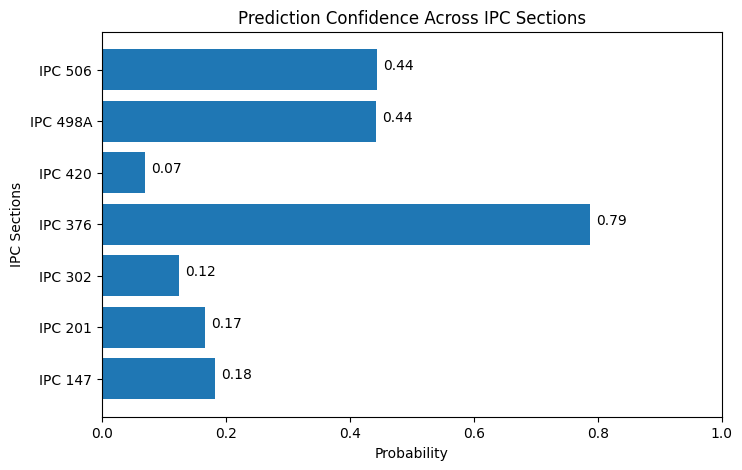

In [22]:
# ==========================================
# CELL 17 : CONFIDENCE PROBABILITY CHART
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

def plot_confidence(legal_text):

    # Generate embedding
    case_embedding = model.encode([legal_text], convert_to_numpy=True)

    # Predict probabilities
    probabilities = loaded_classifier.predict_proba(case_embedding)[0]

    ipc_labels = loaded_mlb.classes_

    plt.figure(figsize=(8,5))

    plt.barh(ipc_labels, probabilities)

    plt.xlim(0,1)

    plt.xlabel("Probability")
    plt.ylabel("IPC Sections")
    plt.title("Prediction Confidence Across IPC Sections")

    for i, v in enumerate(probabilities):
        plt.text(v + 0.01, i, f"{v:.2f}")

    plt.show()


# Example

plot_confidence("""
The accused entered the victim's house during the night and
committed rape while threatening the victim with a knife.
""")

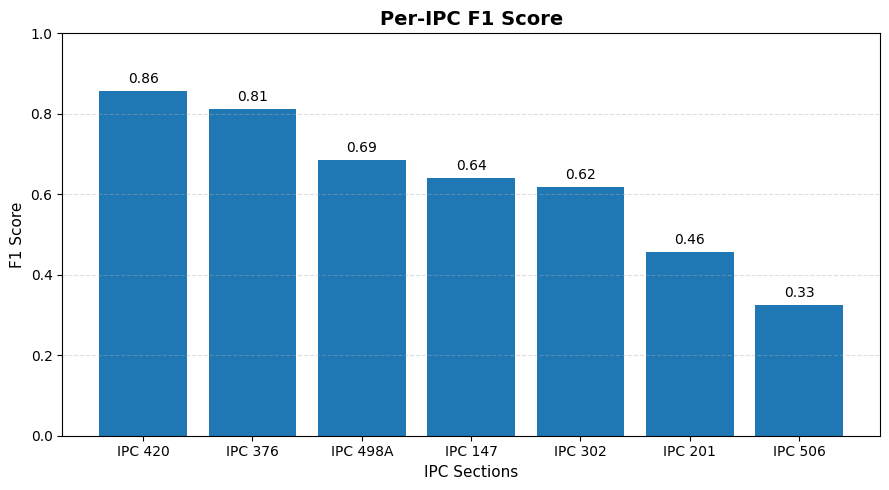

In [23]:
# ==========================================
# CELL 18 : PER-IPC F1 SCORE VISUALIZATION
# ==========================================

from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Generate classification report
report = classification_report(
    test_labels,
    predictions,
    target_names=loaded_mlb.classes_,
    output_dict=True,
    zero_division=0
)

# Extract F1 scores
f1_df = pd.DataFrame({
    "IPC Section": loaded_mlb.classes_,
    "F1 Score": [report[label]["f1-score"] for label in loaded_mlb.classes_]
})

# Sort from highest to lowest
f1_df = f1_df.sort_values(by="F1 Score", ascending=False)

# Plot
plt.figure(figsize=(9,5))

bars = plt.bar(
    f1_df["IPC Section"],
    f1_df["F1 Score"]
)

plt.ylim(0,1)
plt.xlabel("IPC Sections", fontsize=11)
plt.ylabel("F1 Score", fontsize=11)
plt.title("Per-IPC F1 Score", fontsize=14, weight="bold")

# Display score above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.02,
        f"{height:.2f}",
        ha='center',
        fontsize=10
    )

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [24]:
# ==========================================
# CELL 19 : INSTALL GRADIO FOR WEB INTERFACE
# ==========================================

!pip -q install gradio

In [ ]:
# ==========================================
# CELL 20 : CREATE AND LAUNCH GRADIO WEB UI
# ==========================================

import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def predict_and_explain_ui(legal_text, top_k=5):
    # 1. Process Embeddings
    case_embedding = model.encode([legal_text], convert_to_numpy=True)

    # 2. Predict IPC Sections and Probabilities
    prediction = loaded_classifier.predict(case_embedding)
    predicted_labels = loaded_mlb.inverse_transform(prediction)[0]
    probabilities = loaded_classifier.predict_proba(case_embedding)[0]

    # Formulate Predictions Text
    if len(predicted_labels) == 0:
        pred_text = "⚠️ No IPC Section Predicted with current confidence thresholds."
    else:
        pred_text = "\n".join([f"✅ {ipc}" for ipc in predicted_labels])

    # 3. Create Confidence Bar Chart
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ipc_labels = loaded_mlb.classes_
    y_pos = np.arange(len(ipc_labels))

    bars = ax.barh(y_pos, probabilities, color='#2196F3')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(ipc_labels)
    ax.invert_yaxis()  # top-down
    ax.set_xlabel('Probability')
    ax.set_xlim(0, 1.0)
    ax.set_title('Prediction Confidence')

    # Add labels to bars
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.2f}',
                ha='left', va='center', fontsize=9)

    plt.tight_layout()

    # 4. Evidence Retrieval
    sim_scores = cosine_similarity(case_embedding, evidence_embeddings)[0]
    top_indices = sim_scores.argsort()[-int(top_k):][::-1]

    evidence_data = []
    for rank, idx in enumerate(top_indices, start=1):
        evidence_data.append({
            "Rank": rank,
            "Document": sentence_df.iloc[idx]["doc_id"],
            "Relevant IPC": sentence_df.iloc[idx]["ipc"],
            "Similarity Score": f"{sim_scores[idx]:.4f}",
            "Evidence Sentence": sentence_df.iloc[idx]["sentence"]
        })

    evidence_df = pd.DataFrame(evidence_data)

    return pred_text, fig, evidence_df

# Design the Gradio Interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# ⚖️ Legal IPC Section Classifier & Evidence Finder")
    gr.Markdown("Enter a legal narrative below to predict relevant Indian Penal Code (IPC) sections and find matching legal precedents.")

    with gr.Row():
        with gr.Column(scale=2):
            input_text = gr.Textbox(
                label="Legal Case Facts / Description",
                placeholder="Type or paste legal case details here...",
                lines=8
            )
            top_k_slider = gr.Slider(
                minimum=1,
                maximum=10,
                value=5,
                step=1,
                label="Number of Evidence Sentences to Retrieve"
            )
            submit_btn = gr.Button("🔮 Predict IPC & Find Evidence", variant="primary")

        with gr.Column(scale=1):
            output_ipcs = gr.Textbox(label="Predicted IPC Sections", interactive=False)
            output_plot = gr.Plot(label="Confidence Chart")

    with gr.Row():
        output_evidence = gr.Dataframe(
            label="Supporting Evidence Sentences",
            wrap=True
        )

    submit_btn.click(
        fn=predict_and_explain_ui,
        inputs=[input_text, top_k_slider],
        outputs=[output_ipcs, output_plot, output_evidence]
    )

# Launch Web Interface directly in Colab
demo.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ceef8634957df6936d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
